# M00-1 | torch.export 出來的圖長什麼樣，以及 ATen 是什麼

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/bobondemon/pt2e_quantize_and_deploy/blob/main/m00_export_basics/01_export_and_inspect.ipynb)

PT2E 的每一步都在 `torch.export` 產生的圖上進行。這本 notebook 分兩段：

- **A. export 之後的圖**：`torch.export.export()` 回傳什麼、`ep.module()` 又是什麼、每個 node 上帶了哪些資訊。
- **B. ATen 是什麼**：`aten.conv2d.default` 這串名字怎麼讀；為什麼不同的 Python 寫法，export 之後會變成同一串 op。

In [ ]:
#| include: false
# 在 Google Colab 上執行時：下載本教材的程式並安裝套件（第一次約需幾分鐘）。
# 在自己的電腦上執行時（環境見 README），這一格什麼都不做。
import sys

if "google.colab" in sys.modules:
    import os
    import subprocess

    repo = "/content/pt2e_quantize_and_deploy"
    if not os.path.exists(repo):
        subprocess.run(["git", "clone", "-q", "--depth", "1",
                        "https://github.com/bobondemon/pt2e_quantize_and_deploy.git", repo], check=True)
        subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                        "--extra-index-url", "https://download.pytorch.org/whl/cpu",
                        "torch==2.14.0+cpu", "torchao==0.18.0", "onnx==1.23.0", "onnxscript==0.7.2",
                        "onnxruntime==1.30.0", "tabulate", "graphviz"], check=True)
    sys.path.insert(0, repo)  # 讓 notebook 能 import 本教材的 common/
    os.chdir(f"{repo}/m00_export_basics")

In [1]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.export import export

from common.graph_utils import node_rows, short
from common.models import example_inputs, get_model
from common.pt2e import quiet
from common.viz import draw_stages, table

quiet()
_ = torch.manual_seed(0)

## A. export 之後的圖

模型是 `ConvBnReLU`（conv → bn → relu），先呼叫 `.eval()`（為什麼要先決定 eval／train，見 M00-2）。

### A1. `torch.export.export()` 回傳 ExportedProgram

`ExportedProgram`（下面叫 `ep`）有三樣東西：圖 `ep.graph`、說明圖上每個輸入是什麼的 `ep.graph_signature`、以及參數和 buffer 的值 `ep.state_dict`。
在 `ep.graph` 裡，參數、buffer 和使用者的輸入 `x` **都是 placeholder**（圖的輸入）。
`graph_signature` 負責記下哪些 placeholder 是模型狀態、對應原模型的哪個欄位：

In [2]:
model = get_model("conv_bn_relu").eval()
ex = example_inputs()
ep = export(model, ex)

table([[spec.arg.name, spec.kind.name, spec.target] for spec in ep.graph_signature.input_specs],
      ["placeholder", "kind", "target（原模型的欄位）"])

placeholder,kind,target（原模型的欄位）
p_conv_weight,PARAMETER,conv.weight
p_bn_weight,PARAMETER,bn.weight
p_bn_bias,PARAMETER,bn.bias
b_bn_running_mean,BUFFER,bn.running_mean
b_bn_running_var,BUFFER,bn.running_var
b_bn_num_batches_tracked,BUFFER,bn.num_batches_tracked
x,USER_INPUT,


名稱前綴 `p_`（parameter）、`b_`（buffer）只是方便閱讀的慣例；可靠的分類是 `kind`。
只有 `x` 的 kind 是 `USER_INPUT`，其他都是模型狀態。

### A2. `ep.module()` 回傳 GraphModule

PT2E 的 `prepare_pt2e` 吃的是 `ep.module()`：它依 `graph_signature` 把 `state_dict` 綁回去，得到一個可以直接呼叫的 `GraphModule`。
下圖上面是 `ep.graph`，下面是 `ep.module()` 的圖；這次把參數也畫成獨立的 node（`show_params=True`）。

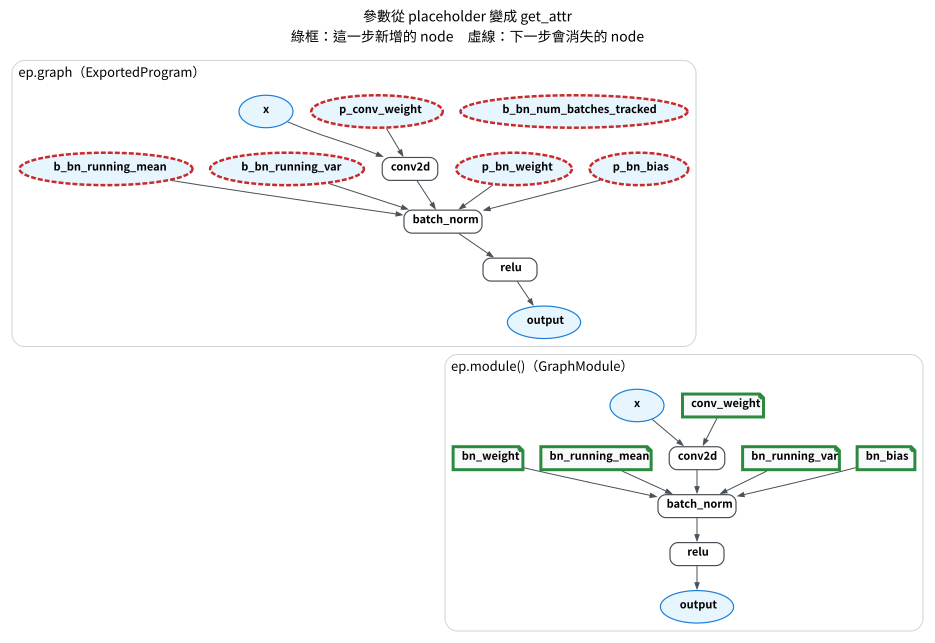

In [3]:
gm = ep.module()
draw_stages([(ep.graph_module, "ep.graph（ExportedProgram）"), (gm, "ep.module()（GraphModule）")],
            show_params=True, per_row=1, title="參數從 placeholder 變成 get_attr")

請看三件事：

- 上面的 `p_conv_weight`、`b_bn_running_mean`… 是 placeholder（橢圓，下一步消失）；下面變成 `get_attr`（摺角方塊，綠框），從 GraphModule 自己身上讀屬性。
- `nn.Conv2d`、`nn.BatchNorm2d` 這些 module 不見了，只剩 `conv2d`、`batch_norm`、`relu` 三個運算。整張圖是**扁平**的：沒有 module 的階層，只有一串 op。
  所以 PT2E 要找「conv 後面接 relu」只能比對圖上的 op 樣式，不可能靠「換掉某個 module」。
- `b_bn_num_batches_tracked` 在 eval 模式下沒有人用（M00-2 會看到 train 模式下誰用它）。

逐 node 列出來。`op` column 就是 fx node 的種類：

In [4]:
table([row[:4] for row in node_rows(gm, show_args=False)], ["#", "op", "name", "target"])

#,op,name,target
0,get_attr,conv_weight,conv.weight
1,get_attr,bn_weight,bn.weight
2,get_attr,bn_bias,bn.bias
3,get_attr,bn_running_mean,bn.running_mean
4,get_attr,bn_running_var,bn.running_var
5,get_attr,bn_num_batches_tracked,bn.num_batches_tracked
6,placeholder,x,x
7,call_module,_guards_fn,_guards_fn
8,call_function,conv2d,conv2d
9,call_function,batch_norm,batch_norm


- `placeholder`：圖的輸入；`get_attr`：讀 GraphModule 上的參數或 buffer；`call_function`：呼叫一個函式（這裡都是 ATen op）；`output`：圖的輸出。
- `call_module` 的 `_guards_fn` 是 `ep.module()` 預設插入的檢查：呼叫時確認輸入符合 export 時的假設（例如 shape），與量化無關。前面的圖沒有畫它。

`get_attr` 的 target 正是 `graph_signature` 裡的 target，`ep.module()` 的輸出也和原模型完全相同：

In [5]:
targets = {spec.target for spec in ep.graph_signature.input_specs if spec.target is not None}
assert {n.target for n in gm.graph.nodes if n.op == "get_attr"} == targets
with torch.no_grad():
    err = (model(*ex) - gm(*ex)).abs().max().item()
print(f"model(x) 與 ep.module()(x) 的最大誤差 = {err}")
assert err == 0

model(x) 與 ep.module()(x) 的最大誤差 = 0.0


### A3. 每個 node 的 meta

每個 node 有一個 `meta` 字典，記錄 export 時收集到的資訊。其中最常用的是 `meta["val"]`：
export 用「假的 tensor」（FakeTensor，只有 shape、dtype、device，沒有數值）跑過一遍模型，記下這個 node 會產生什麼。

In [6]:
rows = []
for n in gm.graph.nodes:
    if n.op == "call_function":
        val = n.meta["val"]
        rows.append([n.name, type(val).__name__, str(list(val.shape)), ", ".join(sorted(n.meta))])
table(rows, ["node", "meta['val'] 的型別", "shape", "meta 的 keys"])

node,meta['val'] 的型別,shape,meta 的 keys
conv2d,FakeTensor,"[2, 8, 16, 16]","from_node, nn_module_stack, stack_trace, tensor_meta, torch_fn, val"
batch_norm,FakeTensor,"[2, 8, 16, 16]","from_node, nn_module_stack, stack_trace, tensor_meta, torch_fn, val"
relu,FakeTensor,"[2, 8, 16, 16]","from_node, nn_module_stack, stack_trace, tensor_meta, torch_fn, val"


shape 的第 0 維是 2，因為 example input 的 batch 是 2；export 預設把 shape 寫死（`common.pt2e.export_module()` 會把 batch 設成動態，M01 起都用它）。

現在 meta 裡還沒有量化相關的東西。之後 quantizer 的標註也會寫進同一個 `meta`，key 是 `quantization_annotation`（M01-2、M03）。

**思考題**：這張圖裡 conv2d 的 weight 是從哪一個 node 來的？

In [7]:
conv = next(n for n in gm.graph.nodes if n.name == "conv2d")
weight_node = conv.args[1]
print(f"conv2d.args[1] = {weight_node.name}（op={weight_node.op}, target={weight_node.target}）")
assert weight_node.op == "get_attr"

conv2d.args[1] = conv_weight（op=get_attr, target=conv.weight）


答案：來自 `get_attr` node `conv_weight`（target 是 `conv.weight`），它是 `conv2d` 的第 1 個參數。
之後量化 weight 的標註，就掛在使用它的 `conv2d` node 上：「conv2d 的 weight 那條輸入邊要用什麼規格」。

## B. ATen 是什麼？

### B1. `aten.conv2d.default` 這串名字怎麼讀

圖上 `conv2d` node 的 `target` 是 `torch.ops.aten.conv2d.default`。它由三段組成：

In [8]:
conv_op = torch.ops.aten.conv2d
print(f"torch.ops.aten.conv2d             {type(conv_op).__name__}：一個 op 的所有 overload")
print(f"torch.ops.aten.conv2d.overloads() {conv_op.overloads()}")
print(f"torch.ops.aten.conv2d.default     {type(conv_op.default).__name__}：其中一個 overload")
print(f"  簽名：{conv_op.default._schema}")
print(f"對照 torch.ops.aten.add.Tensor")
print(f"  簽名：{torch.ops.aten.add.Tensor._schema}")
assert conv.target is torch.ops.aten.conv2d.default

torch.ops.aten.conv2d             OpOverloadPacket：一個 op 的所有 overload
torch.ops.aten.conv2d.overloads() ['default', 'padding']
torch.ops.aten.conv2d.default     OpOverload：其中一個 overload
  簽名：aten::conv2d(Tensor input, Tensor weight, Tensor? bias=None, SymInt[2] stride=[1, 1], SymInt[2] padding=[0, 0], SymInt[2] dilation=[1, 1], SymInt groups=1) -> Tensor
對照 torch.ops.aten.add.Tensor
  簽名：aten::add.Tensor(Tensor self, Tensor other, *, Scalar alpha=1) -> Tensor


`aten`（名稱空間）`.conv2d`（op）`.default`（overload）。同一個 op 可以依參數型別有好幾個版本，
例如 `add` 有 `add.Tensor`（兩個 tensor 相加）、`add.Scalar`（tensor 加一個數）等。

**ATen** 是 PyTorch 的核心 tensor 函式庫，其他 Python／C++ 介面幾乎都建在它上面（[官方 C++ 文件](https://docs.pytorch.org/cppdocs/)）；
`torch.ops.aten.*` 是它在 Python 端的 op 名稱。

### B2. 三種寫法，export 之後是同一串 op

同一個模型（conv → relu → 平均 → linear）用三種 Python 寫法：

In [9]:
class FunctionalStyle(nn.Module):
    """全部用 torch.nn.functional 寫，參數自己宣告。"""

    def __init__(self):
        super().__init__()
        self.w = nn.Parameter(torch.randn(8, 3, 3, 3))
        self.fc_w = nn.Parameter(torch.randn(4, 8))

    def forward(self, x):
        return F.linear(F.relu(F.conv2d(x, self.w, padding=1)).mean((2, 3)), self.fc_w)


class Inner(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv = nn.Conv2d(3, 8, 3, padding=1, bias=False)
        self.act = nn.ReLU()

    def forward(self, x):
        return self.act(self.conv(x))


class WrappedStyle(nn.Module):
    """自訂 Module 再包 nn.Conv2d／nn.ReLU／nn.Linear，多一層 Python 類別。"""

    def __init__(self):
        super().__init__()
        self.inner = Inner()
        self.fc = nn.Linear(8, 4, bias=False)

    def forward(self, x):
        return self.fc(self.inner(x).mean((2, 3)))


class SequentialStyle(nn.Module):
    """用 nn.Sequential 寫。"""

    def __init__(self):
        super().__init__()
        self.body = nn.Sequential(nn.Conv2d(3, 8, 3, padding=1, bias=False), nn.ReLU())
        self.fc = nn.Linear(8, 4, bias=False)

    def forward(self, x):
        return self.fc(self.body(x).mean((2, 3)))

每種寫法用兩種方式抓圖，列出圖上的運算 node：

- `torch.fx.symbolic_trace(model)`：fx 原本的抓圖方式（PT2E 之前的 FX graph mode 量化用它）。
- `torch.export.export(model, (x,)).module()`：PT2E 用的方式。

In [10]:
def fx_ops(gm):
    """symbolic_trace 的圖：call_module 印模組類別（與它在模型裡的路徑），call_function 印函式名，call_method 印方法名。"""
    out = []
    for n in gm.graph.nodes:
        if n.op == "call_module":
            out.append(f"module {type(gm.get_submodule(n.target)).__name__}({n.target})")
        elif n.op == "call_function":
            out.append(f"function {n.target.__name__}")
        elif n.op == "call_method":
            out.append(f"method {n.target}")
    return out


def export_ops(gm):
    return [n.target for n in gm.graph.nodes if n.op == "call_function"]


ex_small = (torch.randn(2, 3, 8, 8),)
styles = [FunctionalStyle, WrappedStyle, SequentialStyle]
fx_lists = [fx_ops(torch.fx.symbolic_trace(cls())) for cls in styles]
export_lists = [export_ops(export(cls().eval(), ex_small).module()) for cls in styles]
table([[cls.__name__, " → ".join(f), " → ".join(short(t) for t in e)]
       for cls, f, e in zip(styles, fx_lists, export_lists)],
      ["寫法", "symbolic_trace 的 node", "export 的 node（aten.*）"])

寫法,symbolic_trace 的 node,export 的 node（aten.*）
FunctionalStyle,function conv2d → function relu → method mean → function linear,conv2d → relu → mean → linear
WrappedStyle,module Conv2d(inner.conv) → module ReLU(inner.act) → method mean → module Linear(fc),conv2d → relu → mean → linear
SequentialStyle,module Conv2d(body.0) → module ReLU(body.1) → method mean → module Linear(fc),conv2d → relu → mean → linear


In [11]:
assert all(e == export_lists[0] for e in export_lists)  # export：三種寫法的 node.target 完全相同
assert len({tuple(f) for f in fx_lists}) == 3  # symbolic_trace：三種寫法各不相同
print("export 的 node.target：", [str(t) for t in export_lists[0]])

export 的 node.target： ['aten.conv2d.default', 'aten.relu.default', 'aten.mean.dim', 'aten.linear.default']


- **symbolic_trace** 的圖跟著寫法走：`nn.Conv2d` 留成 `call_module`（module 層級，連它在模型裡的路徑 `inner.conv`、`body.0` 都留著），
  `F.conv2d` 是一個 Python 函式，`.mean()` 是一個 method。
  同一個 conv 有好幾種長相，拿到這張圖的人得認得每一種 Module 類別和每一種 Python 寫法。
- **export** 的圖不管怎麼寫，都是同一串 `aten.*` op；module 的階層也被攤平了。

這對後端很重要：後端拿到圖，要逐個 node 判斷「我有沒有這個運算的 kernel」。圖的詞彙統一成 ATen op，後端只要對照自己支援的 op 清單即可。
PyTorch 文件也這樣定位 Core ATen 這組 op：它是 "designed to serve as the functional IR to interface with backends"
（[IRs](https://docs.pytorch.org/docs/main/user_guide/torch_compiler/torch.compiler_ir.html)）。
PT2E 的 quantizer 用 `node.target == torch.ops.aten.conv2d.default` 找 conv，也是靠這一點（M03）。
本章概覽對這件事有更完整的說明。

### B3. 由上到下的層次

| 層 | 是什麼 | 在 export 的圖裡 |
|---|---|---|
| `nn.Conv2d`、自訂 Module | Python 類別 | export 之後消失 |
| `F.conv2d` | Python 函式 | export 之後消失 |
| `torch.ops.aten.conv2d.default` | op 的名稱 | 就是 `node.target` |
| 各裝置上的 C++ 實作（kernel） | 實際計算的程式 | 不在圖上，執行時才選用（B4） |

ATen op 還能再拆成更底層的 op（例如 `conv2d` → `convolution`），見 M00-3。

### B4. op 執行時怎麼找到 kernel

export 只在圖上留下 op 的**名稱**。真正執行時（eager 模式，以 `z = x + y`、x 與 y 都是 CPU tensor 為例）：

1. Python 的 `x + y` 呼叫 `torch.add`，進入 ATen 的 `aten::add.Tensor`。
2. **dispatcher** 看 tensor 的 dispatch key，決定走哪一層實作：backend（CPU／CUDA／MPS…）、autograd、quantized 等。需要梯度時會先經過 autograd 那一層。
3. backend 的 kernel 執行：ATen 自己帶有 CPU、CUDA、MPS 的實作；有些 op 會再呼叫 cuBLAS、cuDNN 這類函式庫。
4. dtype（float32 等）通常在 kernel 內部再切換，不是 dispatcher 那一層決定的。
5. 結果包成 Tensor 回傳 Python。

dispatch 之後，kernel 內部還可能依輸入再選實作（M07-1 用 profiler 看到 conv 依 batch size 切換實作）。
以上是一般說明，各步驟的先後沒有逐行追過原始碼。

## 小結

- `torch.export.export()` 回傳 ExportedProgram：參數是 placeholder，`graph_signature` 記下對應；`ep.module()` 把參數綁回成 `get_attr`，PT2E 用這個 GraphModule。
- 圖是扁平的，只剩 ATen op；每個 node 的 `meta["val"]` 記著輸出的 shape／dtype，量化標註之後也寫在 `meta`。
- 不同的 Python 寫法 export 成同一串 ATen op，後端與 quantizer 只需要認得這組 op。